# Week 6, session 2: preparing images for a model (in-class exercises)

**Computational AI · Dr Mabrouka Abuhmida · University of South Wales**

In session 1 we looked at the coins image and cleaned the noise. Today we prepare images for a model. The order matters: resize, then scale, then augment, and learn anything from the training images only. This is the same rule you used in Weeks 2, 3 and 5: learn on train, apply to test.

1. Resize an image and see what a wrong aspect ratio does
2. Scale pixel values and check the range
3. Find and fix a leak
4. Decide which augmentations are safe for which task
5. Do the sums on a training set
6. Consolidate: prepare a train and test set from start to finish

Work in pairs. Write short answers wherever you see **Your answer**.

**Submission:** when you finish, run all cells (Kernel > Restart and Run All) and upload this notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## Dataset instructions

- The image is `skimage.data.coins`, the same one as session 1. There is **no file to upload**.
- Libraries: `numpy`, `matplotlib`, `pandas`, `scikit-image` (version 0.21 or later).
- We cut the image into 12 tiles (3 rows by 4 columns). The first 8 tiles are the training set and the last 4 are the test set. It is a toy split, chosen so you can see every step.
- The bottom row of the picture, which is the test set, is darker than the top. Keep an eye on that.

## Setup and data loading

Run this cell as it is.

In [1]:
%pip install scikit-image


Note: you may need to restart the kernel to use updated packages.


shape: (303, 384)  ratio rows/columns: 0.79
dtype: uint8  min: 1  max: 252


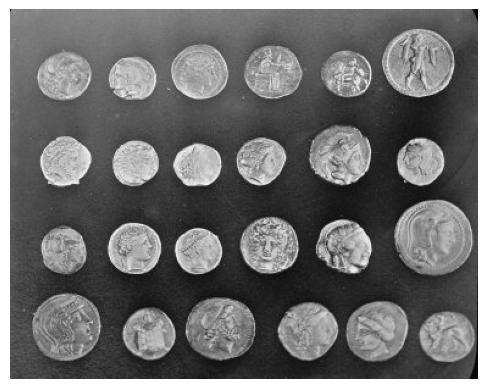

The image array is as follows
[[0.18431373 0.48235294 0.52156863 ... 0.05490196 0.01176471 0.04705882]
 [0.36470588 0.56470588 0.56862745 ... 0.04705882 0.02745098 0.02745098]
 [0.49411765 0.57647059 0.56078431 ... 0.00784314 0.05098039 0.01176471]
 ...
 [0.31764706 0.30980392 0.29019608 ... 0.02352941 0.01568627 0.02745098]
 [0.34509804 0.32156863 0.29019608 ... 0.01960784 0.02745098 0.03137255]
 [0.35686275 0.30980392 0.26666667 ... 0.01568627 0.03921569 0.02745098]]


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from skimage import data, util, transform

coins = data.coins()
coins_f = util.img_as_float(coins)     # floats from 0 to 1
print("shape:", coins.shape, " ratio rows/columns:", round(coins.shape[0] / coins.shape[1], 2))
print("dtype:", coins.dtype, " min:", coins.min(), " max:", coins.max())

plt.imshow(coins_f, cmap="gray")
plt.axis("off")
plt.show()
print("The image array is as follows")
print(coins_f)

## Worked example: resize

Most models need every image to be the same size. `transform.resize(image, (rows, columns))` returns a new image of that shape.

- It expects an array and a target shape.
- It returns floats from 0 to 1 for a uint8 input.
- **Risk:** if the new shape has a different ratio from the original, the picture is stretched.

This cell is complete.

original: (303, 384)  128 by 128: (128, 128)  64 by 64: (64, 64)


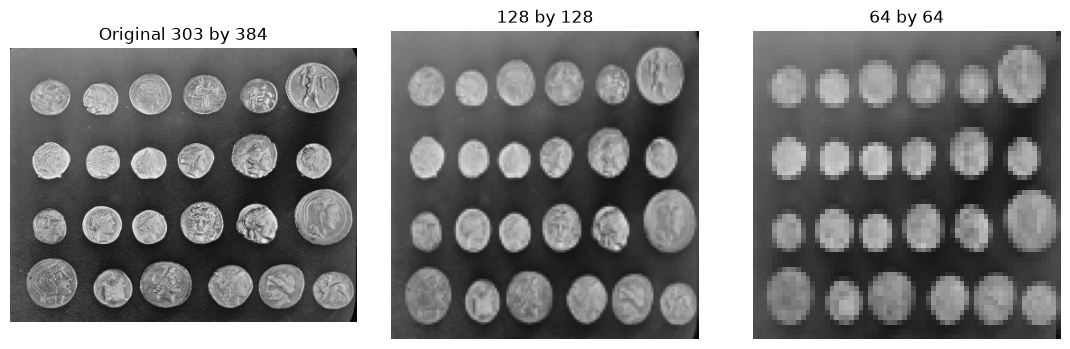

In [8]:
square = transform.resize(coins_f, (128, 128))
small = transform.resize(coins_f, (64, 64))
print("original:", coins_f.shape, " 128 by 128:", square.shape, " 64 by 64:", small.shape)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, (title, img) in zip(axes, [("Original 303 by 384", coins_f), ("128 by 128", square), ("64 by 64", small)]):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Student Task 1: stretch it (slide exercise 1)

**Goal:** see why aspect ratio matters.

**Steps:**
1. Resize `coins_f` to 64 by 128 and call the result `wide`.
2. Resize it to 64 by 81 and call the result `kept`. (The original ratio is 0.79, and 64 divided by 0.79 is about 81.)
3. Show the original, `wide` and `kept` side by side. Print each ratio of rows to columns.

**Expected output:** `wide` has a ratio of 0.5 and the coins look like wide ovals. `kept` has a ratio of 0.79 and the coins are round.

**Reflection question:** why would a model trained on stretched coins struggle on photos that were not stretched?

In [ ]:
# TODO: Complete this task
# Hint: transform.resize(coins_f, (rows, columns))
# Hint: ratio = rows / columns
# Add your code here

**Your answer:**

_Write here._

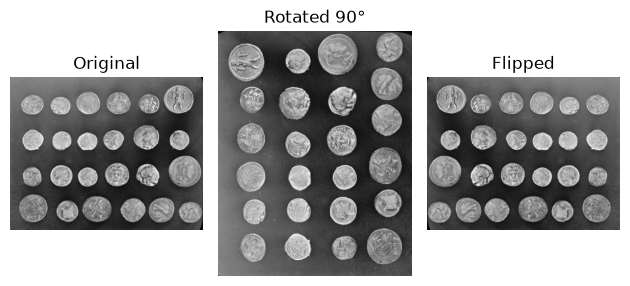

In [13]:
rotated = np.rot90(coins_f)       # Rotate 90° anticlockwise
flipped = np.fliplr(coins_f)      # Flip left to right

fig, axes = plt.subplots(1, 3)

images = [coins_f, rotated, flipped]
titles = ["Original", "Rotated 90°", "Flipped"]

for i in range(3):
    axes[i].imshow(images[i], cmap="gray")
    axes[i].set_title(titles[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Worked example: interpolation

When we shrink an image, `transform.resize` has to decide each new pixel's value. `order` sets the method: 0 is nearest neighbour, 1 is bilinear and 3 is bicubic.

- Nearest copies the closest pixel: fast but blocky.
- Bilinear averages the 4 nearest pixels.
- Bicubic uses 16 pixels and is smoother, but slower.

This cell is complete. Look at the edges of the coins.

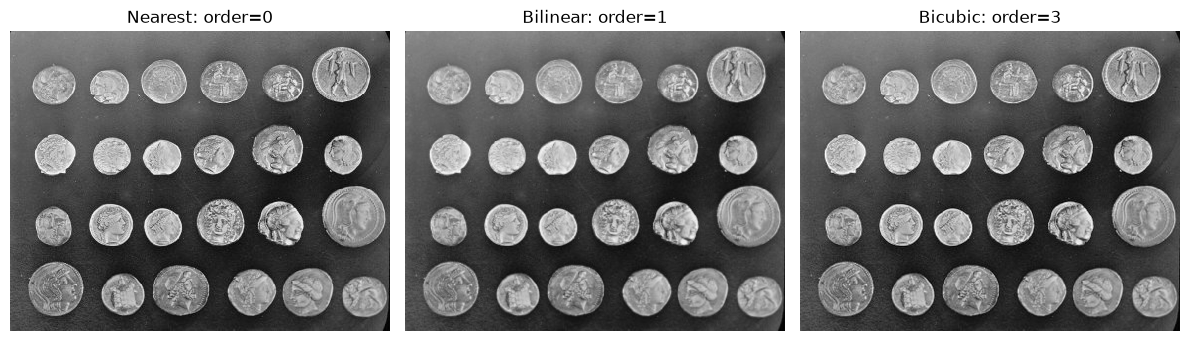

In [17]:
from skimage.transform import resize
import matplotlib.pyplot as plt# Double the image's height and width
new_size = (coins_f.shape[0] * 2, coins_f.shape[1] * 2)
nearest = resize(coins_f, new_size, order=0)
bilinear = resize(coins_f, new_size, order=1)
bicubic = resize(coins_f, new_size, order=3)
images = [nearest, bilinear, bicubic]
titles = ["Nearest: order=0", "Bilinear: order=1", "Bicubic: order=3"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i in range(3):    
    axes[i].imshow(images[i], cmap="gray", interpolation="nearest")    
    axes[i].set_title(titles[i])    
    axes[i].axis("off")
plt.tight_layout()
plt.show()


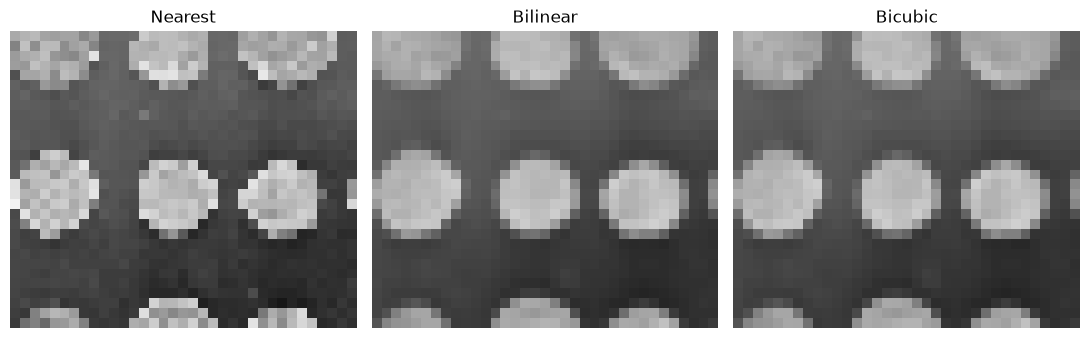

In [19]:
titles = ["Nearest", "Bilinear", "Bicubic"]
orders = [0, 1, 3]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))

for i in range(3):
    img = transform.resize(
        coins_f, (64, 81),
        order=orders[i],
        anti_aliasing=(orders[i] > 0)
    )

    axes[i].imshow(
        img[10:40, 5:40],
        cmap="gray", vmin=0, vmax=1,
        interpolation="nearest"
    )
    axes[i].set_title(titles[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### Student Task 2: check the range (slide exercise 2)

**Goal:** scale pixel values to 0 to 1 and check the result.

**Steps:**
1. Divide the uint8 image `coins` by 255 to make `scaled`.
2. Print the minimum and maximum of `scaled`.
3. Print the minimum and maximum of the original `coins`.

**Expected output:** the minimum is about 0.004 and the maximum is about 0.988.

**Reflection question:** the maximum is not 1. Does that matter, and what would be a different way to scale that always reaches 0 and 1? What is its risk when new images arrive?

In [ ]:
# TODO: Complete this task
# Hint: coins / 255 gives floats
# Hint: min-max scaling is (x - x.min()) / (x.max() - x.min())
# Add your code here

**Your answer:**

_Write here._

## Worked example: cut into tiles and split

We cut the image into 12 tiles, three rows by four columns, each 101 by 96 pixels. The first 8 tiles are the training set and the last 4 are the test set. This is a toy split. It stands in for the images you would collect from different places.

This cell is complete.

In [ ]:
H, W = coins_f.shape
th, tw = H // 3, W // 4
tiles = np.array([coins_f[r*th:(r+1)*th, k*tw:(k+1)*tw] for r in range(3) for k in range(4)])
train_tiles, test_tiles = tiles[:8], tiles[8:]
print("tiles:", tiles.shape)                 # (12, 101, 96)
print("train:", train_tiles.shape[0], " test:", test_tiles.shape[0])
print("mean brightness per tile:", tiles.mean(axis=(1, 2)).round(2))

## Worked example: standardise with training statistics

Standardising turns each value into a number of standard deviations from the mean: `(x - mean) / std`. The mean and standard deviation are **learned**, so they come from the training tiles only. The test tiles are then scaled with those same two numbers.

This is the same rule as week 5, when you fitted `StandardScaler` on train and transformed test.

In [ ]:
train_mean = train_tiles.mean()
train_std = train_tiles.std()
print("train mean:", round(train_mean, 3), " train std:", round(train_std, 3))

train_scaled = (train_tiles - train_mean) / train_std
test_scaled = (test_tiles - train_mean) / train_std
print("test mean in standard deviations (train statistics):", round(test_scaled.mean(), 2))

### Student Task 3: find the leak (slide exercise 3)

**Goal:** spot and fix a leak, and measure what it changes.

The cell below standardises the tiles with the mean and standard deviation of **all 12 tiles**. It runs, and it looks tidy. It is also wrong.

**Steps:**
1. Run the cell and note the test mean it prints.
2. Rewrite it so the statistics come from `train_tiles` only.
3. Print the new test mean and compare.

**Expected output:** with the leak, the test tiles sit at about -0.26 standard deviations. Without it, they sit at about -0.40.

**Reflection question:** the leak made the test tiles look closer to average than they are. Why is that dangerous when the test set is the darker bottom row?

In [ ]:
# This version leaks. Fix it so that the mean and std come from train_tiles only.
all_mean = tiles.mean()
all_std = tiles.std()
test_scaled_leaky = (test_tiles - all_mean) / all_std
print("test mean (leaky):", round(test_scaled_leaky.mean(), 2))

# TODO: write the fixed version below and print its test mean
# Add your code here

**Your answer:**

_Write here._

## Worked example: three augmentations

Augmentation makes new training images from the ones you have. Three common ones:

- `transform.rotate(tile, 15, mode="edge")` turns the tile by 15 degrees. `mode="edge"` fills the corners by repeating the border pixels, not with black.
- `np.fliplr(tile)` mirrors the tile left to right.
- `np.clip(tile + 0.15, 0, 1)` makes the tile brighter. `np.clip` keeps the values inside 0 to 1.

**Risk:** an augmentation must not change the label. We come back to that in Task 4.

This cell is complete.

In [ ]:
def augment(tile):
    return {
        "rotate 15": transform.rotate(tile, 15, mode="edge"),
        "flip left to right": np.fliplr(tile),
        "brighter": np.clip(tile + 0.15, 0, 1),
    }

tile = train_tiles[2]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (title, img) in zip(axes, [("original", tile)] + list(augment(tile).items())):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Student Task 4: safe or not? (slide exercise 4)

**Goal:** decide which augmentations are safe, and defend the decision.

Task A is **count the coins**. Task B is **read the inscription on a coin**.

**Steps:**
1. Fill in the dictionary below with `"safe"`, `"unsafe"` or `"check"` for each augmentation and each task.
2. Print it as a table.
3. In your answer, defend each choice in one sentence.

**Expected output:** a 3 by 2 table. For counting, all three are safe. For reading inscriptions, a flip is unsafe.

**Reflection question:** which augmentation helps most with the difference between a lab and a branch office, and why?

In [ ]:
# TODO: Complete this task
safe_table = {
    "rotate 15":          {"A: count the coins": "...", "B: read the inscription": "..."},
    "flip left to right": {"A: count the coins": "...", "B: read the inscription": "..."},
    "brighter":           {"A: count the coins": "...", "B: read the inscription": "..."},
}
# Add your code here: print pd.DataFrame(safe_table).T

**Your answer:**

_Write here._

## Visualisation 1: the test tiles are darker

This chart shows the mean brightness of each tile. Training tiles are red, test tiles are grey. Look at where the test tiles sit.

In [ ]:
means = tiles.mean(axis=(1, 2))
colours = ["#CA0437"] * 8 + ["#6E6E6E"] * 4
plt.figure(figsize=(8, 3.2))
plt.bar(range(12), means, color=colours)
plt.axhline(train_mean, color="#333333", linestyle="--", label="train mean")
plt.xticks(range(12), [f"T{i+1}" for i in range(12)])
plt.ylabel("mean brightness (0 to 1)")
plt.legend()
plt.title("Red: train tiles. Grey: test tiles.")
plt.tight_layout()
plt.show()

### Student Task 5: do the sums (slide exercise 5)

**Goal:** augment the training tiles only, and count the result.

**Steps:**
1. Make an empty list called `train_aug` and add every training tile to it.
2. For each training tile, call `augment(tile)` and add the three results to the list.
3. Convert the list to an array and print its shape. Print the shape of `test_tiles` too.

**Expected output:** `train_aug` has 32 images (8 originals plus 8 times 3 new ones). `test_tiles` still has 4.

**Reflection question:** why do we never augment the test tiles?

In [ ]:
# TODO: Complete this task
# Hint: list.append(item) adds one item
# Hint: np.array(train_aug).shape gives (images, rows, columns)
# Add your code here

**Your answer:**

_Write here._

### Student Task 6: consolidation, prepare the data from start to finish

**Goal:** repeat the whole session in one clean workflow, with no leak, and record it in a log.

**Steps:**
1. Build `train_tiles` and `test_tiles` again from `tiles` (first 8 and last 4).
2. Augment the training tiles only, keeping the originals.
3. Learn the mean and standard deviation from the **augmented training images**, and apply them to both sets.
4. Print the final shapes, and the mean and standard deviation of the scaled training images and of the scaled test tiles.
5. Build an augmentation log as a DataFrame with the columns `augmentation`, `parameter`, `safe for counting`, `reason`.

**Expected output:** 32 training images, 4 test images. The scaled training images have a mean of 0 and a standard deviation of 1. The test tiles do not, and that is correct: they come from the darker row.

**Reflection question:** the scaled test mean is not zero. Is that a bug? What does it tell you about the branch photos?

In [ ]:
# TODO: Complete this task
# Hint: reuse the augment() function and the loop from Task 5
# Hint: statistics from the 32 augmented training images only
# Add your code here

**Your answer:**

_Write here._

## Post-session task 1: your own photo

**Goal:** prepare one of your own photos with the same workflow.

**Steps:**
1. Load a photo with `skimage.io.imread("your_photo.jpg")` and print its shape and data type.
2. Resize it to 64 pixels high, keeping the ratio.
3. Scale it to 0 to 1 and print the range.
4. Apply the three augmentations and show the four images.
5. Write two sentences: which augmentations are safe for a task you could set, and which are not?

In [ ]:
# TODO: Complete this task
# Add your code here

## Reflection

Weeks 2, 3 and 5 taught you to learn on train and apply to test. Which step in today's session was easiest to get wrong without noticing, and what would you check next time before trusting a prepared image set? Write about 100 words.

**Your answer:**

_Write here._

---

When you finish: Kernel > Restart and Run All, then upload the notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## References

- Gonzalez, R.C. and Woods, R.E. (2018) *Digital image processing*. 4th edn. New York: Pearson.
- Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) 'Leakage in data mining: formulation, detection, and avoidance', *ACM Transactions on Knowledge Discovery from Data*, 6(4), article 15.
- scikit-image contributors (2024) *scikit-image documentation*. Available at: https://scikit-image.org/docs/stable/
- Shorten, C. and Khoshgoftaar, T.M. (2019) 'A survey on image data augmentation for deep learning', *Journal of Big Data*, 6, article 60.
- van der Walt, S., Schönberger, J.L., Nunez-Iglesias, J., Boulogne, F., Warner, J.D., Yager, N., Gouillart, E. and Yu, T. (2014) 'scikit-image: image processing in Python', *PeerJ*, 2, e453.